# Glassdoor Job Reviews
### Exploring Employee Ratings and Workplace Factors

## Introduction

Glassdoor provides employee reviews that reflect different aspects of workplace experiences. This project analyzes employee reviews to explore overall ratings, workplace factors, and differences between selected companies and employee groups.

## Problem Statement

Glassdoor contains a large number of employee reviews, making it difficult to identify differences in workplace experiences across companies. This analysis uses employee review data to compare overall ratings and workplace factors across selected companies and examine how employee ratings change over time.

## Objectives

1. Compare average overall employee ratings across selected companies.

2. Compare workplace factor ratings across selected companies.

3. Analyze changes in employee ratings over time across selected companies.

## Exploratory Data Analysis (EDA)

### Data Info

Getting the data and exploring it, including descriptive statistics.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("glassdoor_reviews.csv")

In [3]:
df.shape

(838566, 18)

## Initial Data Exploration

In [4]:
df.columns

Index(['firm', 'date_review', 'job_title', 'current', 'location',
       'overall_rating', 'work_life_balance', 'culture_values',
       'diversity_inclusion', 'career_opp', 'comp_benefits', 'senior_mgmt',
       'recommend', 'ceo_approv', 'outlook', 'headline', 'pros', 'cons'],
      dtype='object')

In [5]:
df.head()

,firm,date_review,job_title,current,location,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt,recommend,ceo_approv,outlook,headline,pros,cons
0,AFH-Wealth-Management,2015-04-05,,Current Employee,NaN,2,4.0,3.0,NaN,2.0,3.0,3.0,x,o,r,"Young colleagues, poor micro management",Very friendly and welcoming to new staff. Easy...,"Poor salaries, poor training and communication."
1,AFH-Wealth-Management,2015-12-11,Office Administrator,"Current Employee, more than 1 year","Bromsgrove, England, England",2,3.0,1.0,NaN,2.0,1.0,4.0,x,o,r,"Excellent staff, poor salary","Friendly, helpful and hard-working colleagues",Poor salary which doesn't improve much with pr...
2,AFH-Wealth-Management,2016-01-28,Office Administrator,"Current Employee, less than 1 year","Bromsgrove, England, England",1,1.0,1.0,NaN,1.0,1.0,1.0,x,o,x,"Low salary, bad micromanagement",Easy to get the job even without experience in...,"Very low salary, poor working conditions, very..."
3,AFH-Wealth-Management,2016-04-16,,Current Employee,NaN,5,2.0,3.0,NaN,2.0,2.0,3.0,x,o,r,Over promised under delivered,Nice staff to work with,No career progression and salary is poor
4,AFH-Wealth-Management,2016-04-23,Office Administrator,"Current Employee, more than 1 year","Bromsgrove, England, England",1,2.0,1.0,NaN,2.0,1.0,1.0,x,o,x,client reporting admin,"Easy to get the job, Nice colleagues.","Abysmal pay, around minimum wage. No actual tr..."


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 838566 entries, 0 to 838565
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   firm                 838566 non-null  object 
 1   date_review          838566 non-null  object 
 2   job_title            838566 non-null  object 
 3   current              838566 non-null  object 
 4   location             541223 non-null  object 
 5   overall_rating       838566 non-null  int64  
 6   work_life_balance    688672 non-null  float64
 7   culture_values       647193 non-null  float64
 8   diversity_inclusion  136066 non-null  float64
 9   career_opp           691065 non-null  float64
 10  comp_benefits        688484 non-null  float64
 11  senior_mgmt          682690 non-null  float64
 12  recommend            838566 non-null  object 
 13  ceo_approv           838566 non-null  object 
 14  outlook              838566 non-null  object 
 15  headline         

## Data Exploration

In [7]:
df.isnull().sum()

firm                        0
date_review                 0
job_title                   0
current                     0
location               297343
overall_rating              0
work_life_balance      149894
culture_values         191373
diversity_inclusion    702500
career_opp             147501
comp_benefits          150082
senior_mgmt            155876
recommend                   0
ceo_approv                  0
outlook                     0
headline                 2590
pros                        2
cons                       13
dtype: int64

In [8]:
df['overall_rating'].value_counts().sort_index()

overall_rating
1     58958
2     74809
3    194267
4    278277
5    232255
Name: count, dtype: int64

In [9]:
df[['overall_rating', 'work_life_balance', 'culture_values',
    'diversity_inclusion', 'career_opp', 'comp_benefits',
    'senior_mgmt']].mean()

overall_rating         3.655956
work_life_balance      3.375735
culture_values         3.590164
diversity_inclusion    3.966612
career_opp             3.461825
comp_benefits          3.398109
senior_mgmt            3.176576
dtype: float64

In [10]:
df['current'].value_counts()

current
Current Employee                           209599
Former Employee                            146133
Current Employee, more than 1 year          82749
Current Employee, more than 3 years         66471
Former Employee, more than 1 year           65687
Current Employee, less than 1 year          49603
Former Employee, more than 3 years          43614
Former Employee, less than 1 year           41874
Current Employee, more than 5 years         40155
Current Employee, more than 10 years        25029
Former Employee, more than 5 years          23017
Current Employee, more than 8 years         18506
Former Employee, more than 10 years         15411
Former Employee, more than 8 years          10686
Former Contractor, less than 1 year             6
Former Intern, less than 1 year                 5
Current Contractor, less than 1 year            3
Current Contractor, more than 1 year            3
Former Contractor                               2
Former Intern                             

In [11]:
df['firm'].value_counts().head(10)

firm
IBM           60436
McDonald-s    49450
Deloitte      46995
EY            34050
PwC           33227
Oracle        31941
Microsoft     26675
J-P-Morgan    25814
KPMG          24815
Apple         20797
Name: count, dtype: int64

### Data Handling

Cleaning, transforming, and preparing the data for analysis.

In [12]:
df.duplicated().sum()

np.int64(33515)

In [13]:
df = df.drop_duplicates()

In [14]:
df.shape

(805051, 18)

In [15]:
df['employee_status'] = df['current'].str.startswith('Current').map({
    True: 'Current',
    False: 'Former'
})

In [16]:
df['employee_status'].value_counts()

employee_status
Current    471188
Former     333863
Name: count, dtype: int64

In [17]:
df['date_review'] = pd.to_datetime(df['date_review'])

In [18]:
df['review_year'] = df['date_review'].dt.year

### Analysis

Answering the objectives through focused data analysis and meaningful visualizations.

In [19]:
selected_firms = ['Microsoft', 'IBM', 'Oracle']

company_df = df[df['firm'].isin(selected_firms)]

In [20]:
company_ratings = company_df.groupby('firm')['overall_rating'].mean().sort_values(ascending=False)

company_ratings

firm
Microsoft    3.973983
IBM          3.523218
Oracle       3.456468
Name: overall_rating, dtype: float64

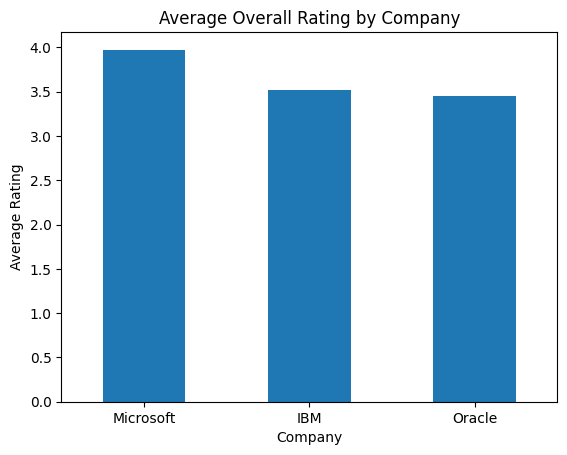

In [21]:
company_ratings.plot(
    kind='bar',
    title='Average Overall Rating by Company',
    ylabel='Average Rating',
    xlabel='Company',
    rot=0
);

### Finding of AVG Rating
Microsoft has the highest average overall employee rating among the three selected technology companies.

In [22]:
company_factors = company_df.groupby('firm')[
    ['work_life_balance', 'culture_values', 'career_opp',
     'comp_benefits', 'senior_mgmt']
].mean()

company_factors

,work_life_balance,culture_values,career_opp,comp_benefits,senior_mgmt
firm,,,,,
IBM,3.628080,3.538551,3.401194,3.089915,2.955730
Microsoft,3.685015,3.849275,3.752507,4.002290,3.331619
Oracle,3.759871,3.260371,3.241511,3.189396,2.996206


In [25]:
import matplotlib.pyplot as plt

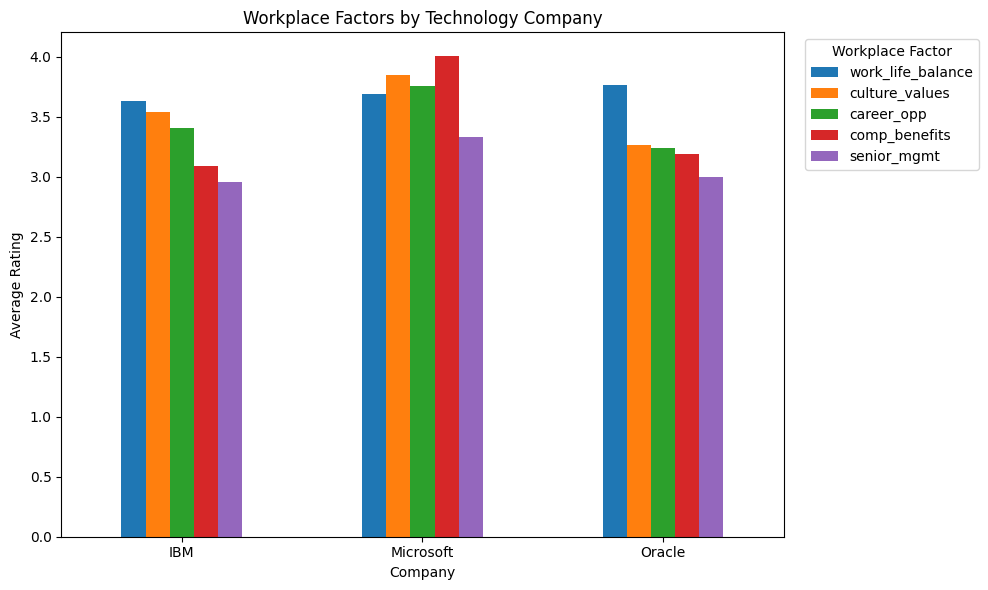

In [26]:
company_factors.plot(
    kind='bar',
    figsize=(10, 6),
    title='Workplace Factors by Technology Company',
    ylabel='Average Rating',
    xlabel='Company',
    rot=0
);

plt.legend(
    title='Workplace Factor',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
);

plt.tight_layout()

### Finding: Workplace Factor Ratings

Microsoft had higher average ratings across most workplace factors, while Oracle had the highest work-life balance rating.

In [27]:
status_ratings = company_df.groupby(
    ['firm', 'employee_status']
)['overall_rating'].mean().unstack()

status_ratings

employee_status,Current,Former
firm,,
IBM,3.601439,3.384117
Microsoft,4.076577,3.783758
Oracle,3.522881,3.322750


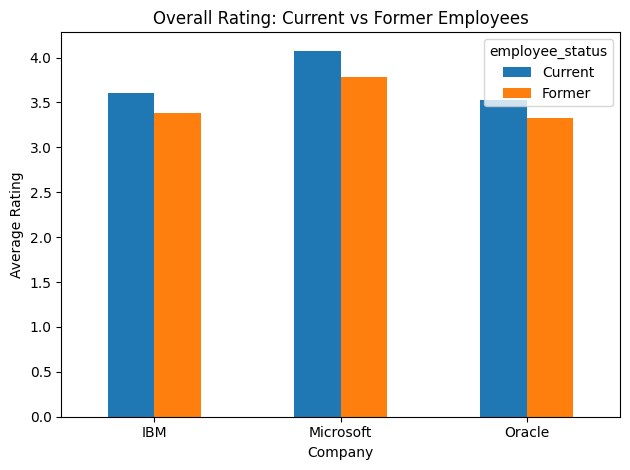

In [28]:
status_ratings.plot(
    kind='bar',
    title='Overall Rating: Current vs Former Employees',
    ylabel='Average Rating',
    xlabel='Company',
    rot=0
);

plt.tight_layout()

### Key Finding

Current employees had higher average overall ratings than former employees across all three companies. Microsoft showed the largest difference between current and former employees.

In [33]:
company_df.groupby('firm')['date_review'].agg(['min', 'max'])

,min,max
firm,,
IBM,2008-05-30,2021-06-05
Microsoft,2008-02-27,2021-06-04
Oracle,2008-03-18,2021-06-06


In [34]:
company_df.groupby(['firm', 'review_year']).size().unstack(0)

firm,IBM,Microsoft,Oracle
review_year,,,
2008,656,602,308
2009,674,382,200
2010,1003,783,469
2011,1095,813,442
2012,1895,1580,1033
2013,1962,1663,1209
2014,2631,2202,1746
2015,3970,3029,2542
2016,5660,2840,3253


In [35]:
yearly_ratings = (
    company_df[company_df['review_year'].between(2009, 2020)]
    .groupby(['review_year', 'firm'])['overall_rating']
    .mean()
    .unstack()
)

yearly_ratings

firm,IBM,Microsoft,Oracle
review_year,,,
2009,2.897626,3.400524,2.970000
2010,2.990030,3.356322,2.953092
2011,3.123288,3.370234,3.106335
2012,3.387863,3.669620,3.388190
2013,3.243629,3.689116,3.385443
2014,3.100722,3.692098,3.315006
2015,3.217884,3.842192,3.361920
2016,3.422792,3.968662,3.396864
2017,3.512434,4.039892,3.411499


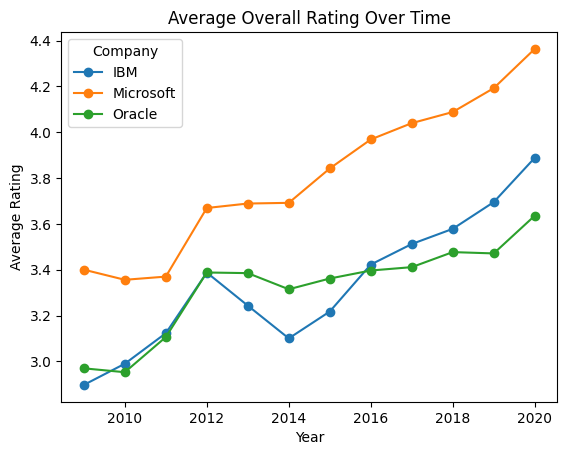

In [36]:
yearly_ratings.plot(
    kind='line',
    marker='o',
    title='Average Overall Rating Over Time',
    ylabel='Average Rating',
    xlabel='Year'
);

plt.legend(title='Company')
plt.show()

### Finding

* Microsoft consistently had the highest average overall rating from 2009 to 2020.
* All three companies showed an overall increase in average ratings over the period.
* Microsoft showed the strongest improvement, increasing from **3.40 in 2009 to 4.36 in 2020**, while IBM increased from **2.90 to 3.89** and Oracle from **2.97 to 3.64**.


## Summary
* Microsoft had the highest average overall rating among the selected technology companies.
* Microsoft had the highest ratings across most workplace factors, while Oracle had the highest work-life balance rating.
* From 2009 to 2020, Microsoft consistently had the highest average overall rating among the three companies.
* Overall ratings increased over time for all three companies, with Microsoft showing the strongest improvement.

## Recommendations/Conclusion

* Companies can focus on workplace factors such as culture, career opportunities, compensation, and senior management to improve employee experiences.
* Employee review data can help companies identify workplace strengths and areas that may need improvement.
* Monitoring employee ratings over time can help companies track changes in workplace experiences.
* Further analysis could examine employee reviews by industry, location, or other available review characteristics.